# 01 · Análisis Exploratorio de Datos (EDA) de la data cruda y su transformación

Este notebook trabaja con la data **cruda** extraída de yahoo finance y se analizan los siguientes aspectos: 
- Calidad y limpieza de los de datos: negativos, faltantes, análisis estadístico de series temporales.
- División de la data en entrenamiento, validación y test.
- Transformación: Mediante pruebas estadísticas como ADF, Correlation Spearman, etc se determina el tipo de transfromación para cada variable (retornos logarítmicos o diferencias).

## 0. Configuración

In [1]:
import sys
from pathlib import Path

# La raíz del proyecto es la carpeta que contiene `src/` (funciona se ejecute desde la raíz o desde notebooks/)
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

In [2]:
RAIZ

WindowsPath('c:/Users/ASUS/Desktop/Maestria IA USFQ/AprendizajeSupervisado/Proyectofinal_ml_wti')

In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

import importlib

from src import config as cfg
import statsmodels.api as sm
from src import load_clean as lc
from src import eda_utils as eda
from src import download_data as dd
from src import preprocessing as pp

from pandas.tseries.holiday import USFederalHolidayCalendar, GoodFriday

In [84]:
importlib.reload(cfg)
importlib.reload(lc)
importlib.reload(dd)
importlib.reload(eda)
importlib.reload(pp)

<module 'src.preprocessing' from 'c:\\Users\\ASUS\\Desktop\\Maestria IA USFQ\\AprendizajeSupervisado\\Proyectofinal_ml_wti\\src\\preprocessing.py'>

## 1. Carga de la data cruda

In [5]:
dd.main()

[*********************100%***********************]  1 of 1 completed


FileExistsError: Ya existe una descarga para 20261113. Cambia el nombre o guarda una nueva versión.

In [6]:
base = lc.load_raw()
print(base.shape, base.index.min().date(), "->", base.index.max().date())
base.head()

(4233, 1) 2010-01-04 -> 2026-10-30


,WTI
Date,
2010-01-04,81.510002
2010-01-05,81.769997
2010-01-06,83.180000
2010-01-07,82.660004
2010-01-08,82.750000


In [7]:
base.index = pd.to_datetime(base.index)
base = base.sort_index()
assert base.index.is_unique

Se extraen los precios de cierre diarios de las variables financieras consideradas en el proyecto. La base contiene 4.233 observaciones entre el 4 de enero de 2010 y el 30 de octubre de 2026. En el caso del WTI, se utiliza el símbolo CL=F de Yahoo Finance, que corresponde a una serie continua de futuros. La fecha identifica la sesión de negociación y el valor de WTI representa el precio de cierre, en dólares por barril, del contrato de futuros que la serie sigue en esa fecha. El contrato específico y su mes de entrega pueden cambiar a lo largo del tiempo.


| Variable | Unidades | Descripción |
|---|---|---|
| `Date` | Fecha (AAAA-MM-DD) | Fecha de la sesión de negociación a la que corresponde el precio de cierre observado. Permite ordenar cronológicamente las series y sincronizar las variables financieras. |
| `WTI` | USD por barril (USD/bbl) | Precio de cierre de la serie continua de futuros de petróleo crudo West Texas Intermediate (WTI), descargada de Yahoo Finance mediante el símbolo CL=F. Representa la cotización del contrato de futuros que la serie sigue en esa fecha; no es necesariamente el precio spot ni el precio de entrega física inmediata. |


Entonces, para leer la información de la data se debe leer de la siguiente forma:


***El día X del mes Y del año Z, el precio de cierre reportado para la serie continua de futuros de petróleo crudo WTI (CL=F) fue de $M por barril.***

La fecha corresponde a la sesión de negociación. El precio es el cierre del contrato que la serie continua sigue en esa fecha; no significa necesariamente que se comprara petróleo físico a ese precio.

Un contrato de futuros es un acuerdo estandarizado para comprar o vender una cantidad determinada de petróleo en un mes futuro, bajo condiciones definidas por el mercado. Los contratos tienen distintos meses de entrega y se negocian diariamente. Como CL=F es una serie continua, va siguiendo contratos sucesivos conforme se acercan sus vencimientos; por eso, cada observación diaria no necesariamente corresponde al mismo contrato.

### 1.1 Calidad de datos faltantes,ceros y negativos

In [8]:
# El índice debe ser datetime, ordenado y sin duplicados
print(base.index.dtype, base.index.is_monotonic_increasing, base.index.duplicated().sum())

datetime64[us] True 0


In [9]:
eda.chequeo_calidad(base).T

,WTI
min,-37.630001
n_<=0,1.000000
n_inf,0.000000
n_nulos,0.000000
n_dias_sin_cambio,14.000000


El chequeo de calidad de la serie WTI muestra que el valor mínimo es −$37,63 por barril y que existe un solo valor menor o igual a cero. No se detectan valores infinitos ni datos nulos. También se identifican 14 días sin variación en el precio, que conviene revisar para confirmar que sean observaciones legítimas y no valores repetidos por algún problema de descarga o relleno.

In [10]:
lc.summarize_negative_values(base)

,cantidad,porcentaje
WTI,1,0.02


In [11]:
lc.rows_with_negative_values(base)

,WTI
Date,
2020-04-20,-37.630001


Se analizan los valores negativos que pudieran afectar las transformaciones de retornos y se encuentra un único valor negativo en la serie, correspondiente al 20 de abril de 2020. Este valor se relaciona con las condiciones excepcionales del mercado petrolero durante la pandemia de COVID-19: la caída abrupta de la demanda y el exceso de oferta elevaron los inventarios y generaron preocupación por la disponibilidad de almacenamiento en Cushing, Oklahoma, punto de entrega del contrato WTI. Además, el contrato de futuros con entrega en mayo estaba próximo a vencer. Algunos operadores que no podían o no querían recibir físicamente el petróleo vendieron sus posiciones a precios negativos, pagando efectivamente para salir del contrato. El cierre de ese contrato fue de −$37,63 por barril.

Por tanto, el valor negativo no debe interpretarse como un error de los datos ni como que todos los tipos de petróleo se vendieron a un precio negativo: corresponde a un contrato específico de futuros de WTI en una situación extraordinaria, cerca de su vencimiento.

Ahora, se van a analizar los días que no muestran grandes variaciones o cambios.

In [12]:
eda.dias_sin_cambio(base)

,serie,fecha_previa,fecha,valor
0,WTI,2010-07-23,2010-07-26,78.980003
1,WTI,2010-11-10,2010-11-11,87.809998
2,WTI,2017-09-14,2017-09-15,49.889999
3,WTI,2018-05-16,2018-05-17,71.489998
4,WTI,2018-11-15,2018-11-16,56.459999
5,WTI,2019-12-04,2019-12-05,58.430000
6,WTI,2020-02-14,2020-02-18,52.049999
7,WTI,2020-04-15,2020-04-16,19.870001
8,WTI,2020-08-17,2020-08-18,42.889999
9,WTI,2021-09-15,2021-09-16,72.610001


La U.S. Energy Information Administration (EIA) (https://www.eia.gov/dnav/pet/hist/RCLC1D.htm) es una agencia independiente del Departamento de Energía de Estados Unidos que recopila y publica información sobre los mercados energéticos. Al comparar los precios de la serie WTI con los valores de futuros publicados por la EIA, no se encontraron errores anormales ni indicios de errores de digitación. Los días sin cambio corresponden a valores de cierre repetidos entre sesiones consecutivas; estos pueden deberse a condiciones del mercado o a diferencias en el registro y publicación de los datos, por lo que no se consideran errores sin evidencia adicional.

### 1.2 Huecos en el calendario

A continuación, se toma la fecha inicial y final de la serie base y se generan las fechas de los feriados federales de Estados Unidos dentro de ese periodo y añade las fechas de Viernes Santo. Luego combina ambas listas y las compara con el índice de base para identificar cuáles de esos feriados aparecen como fechas de observación en la serie. 

Esta comparación ayuda a revisar el calendario, aunque no confirma por sí sola los días oficiales de negociación de los futuros WTI.

In [13]:
inicio = base.index.min()
fin = base.index.max()

feriados_fed = USFederalHolidayCalendar().holidays(
    start=inicio,
    end=fin,
)

viernes_santo = GoodFriday.dates(inicio, fin)

feriados = feriados_fed.union(viernes_santo).sort_values()

print("Feriados generados:", len(feriados))

Feriados generados: 189


In [14]:
base.index = pd.to_datetime(base.index).normalize()

In [15]:
# bdate_range() genera un rango de fechas considerando solo días hábiles (lunes a viernes)
# genera primero todas las fechas de lunes a viernes desde la fecha mínima hasta la máxima de 
# y con .difference(base.index), quita las fechas que sí están en el índice de base. 
# El resultado son las fechas de lunes a viernes que no aparecen en la base.

faltan = pd.bdate_range(base.index.min(), base.index.max()).difference(base.index)
print(len(faltan)); faltan[:20]

157


DatetimeIndex(['2010-01-18', '2010-02-15', '2010-04-02', '2010-05-31',
               '2010-07-05', '2010-09-06', '2010-11-25', '2010-12-24',
               '2011-01-17', '2011-02-21', '2011-04-22', '2011-05-30',
               '2011-07-04', '2011-09-05', '2011-11-24', '2011-12-26',
               '2012-01-02', '2012-01-16', '2012-02-20', '2012-04-06'],
              dtype='datetime64[us]', freq=None)

In [16]:
faltan_sin_feriados = faltan.difference(feriados)

print(len(faltan_sin_feriados))
faltan_sin_feriados[:20]

3


DatetimeIndex(['2012-10-29', '2012-10-30', '2018-12-05'],
              dtype='datetime64[us]', freq=None)

In [17]:
faltan_sin_feriados_df = pd.DataFrame({
    "fecha": faltan_sin_feriados,
})

faltan_sin_feriados_df["dia_semana"] = (
    faltan_sin_feriados_df["fecha"].dt.day_name()
)

In [18]:
faltan_sin_feriados_df

,fecha,dia_semana
0,2012-10-29,Monday
1,2012-10-30,Tuesday
2,2018-12-05,Wednesday


Una vez quitados los feriados federales de USA, se encontró que existen 3 días laborales que se no son feriados y que deben reportar información de mercado dentro de la serie WTI en la que vamos a trabajar, por lo que vamos a validar si aquellos días se encuentran o no en nuestra serie. 

In [19]:

fechas_a_revisar = pd.DatetimeIndex(faltan_sin_feriados_df["fecha"])

faltantes_presentes = fechas_a_revisar.intersection(base.index)

print(f"Fechas que sí están en base: {len(faltantes_presentes)}")
display(faltantes_presentes)

Fechas que sí están en base: 0


DatetimeIndex([], dtype='datetime64[us]', freq=None)

Como se puede observar, ninguna de las tres fechas aparecen en la base madre en la que trabajaremos, y esto se debe a que: 

- Lunes 29 y martes 30 de octubre de 2012 (Huracán Sandy). La Bolsa de Nueva York (NYSE) y demás mercados estadounidenses cerraron sus operaciones por el impacto del huracán Sandy en la costa este. Fue la primera vez desde 1888 que los mercados cerraban durante dos días consecutivos debido a condiciones climáticas.
- Miércoles 5 de diciembre de 2018 (Duelo nacional por George H. W. Bush). El gobierno federal y los principales mercados bursátiles de Estados Unidos suspendieron sus actividades para observar el Día Nacional de Luto tras el fallecimiento del expresidente George H. W. Bush.

### 1.3 Saltos extremos

In [20]:
eda.saltos_extremos(base).T

,0,1,2,3,4
serie,WTI,WTI,WTI,WTI,WTI
fecha_previa,2020-04-21,2020-03-06,2020-04-24,2020-04-17,2020-04-20
fecha,2020-04-22,2020-03-09,2020-04-27,2020-04-20,2020-04-21
precio_previo,10.01,41.279999,16.940001,18.27,-37.630001
precio_actual,13.78,31.129999,12.78,-37.630001,10.01
cambio,3.77,-10.15,-4.160001,-55.900002,47.640001
cambio_pct,37.662332,-24.588178,-24.557265,-305.966065,-126.601116
log_var_abs,0.319634,0.282206,0.281796,NaN,NaN


Todos los saltos extremos  se concentran en el año 2020, durante el choque petrolero de la pandemia: la demanda cayó bruscamente, hubo exceso de oferta y aumentó la preocupación por la capacidad de almacenamiento. El caso más excepcional es el del 20 de abril, cuando el futuro WTI próximo a vencer cerró en −$37,63 por barril; el cambio desde el cierre previo de $18,27 fue de −$55,90. Los movimientos de los días siguientes reflejan el rebote desde ese episodio y la alta volatilidad de esos días.

Los porcentajes alrededor del valor negativo deben interpretarse con cuidado: al pasar de un precio negativo a uno positivo, el porcentaje convencional puede resultar engañoso. Para esos días es más claro comparar los precios y el cambio en dólares por barril. Estos saltos son extremos, pero coherentes con un periodo de mercado excepcional; por sí solos no prueban errores de digitación ni identifican un cambio de contrato.

In [21]:
top10, excluidos = eda.top_movimientos_diarios(base)

display(top10)

,día,cierre_anterior,cierre,retorno_log_%,retorno_simple_%
2020-03-09,Monday,41.28,31.13,-28.22,-24.59
2020-03-18,Wednesday,26.95,20.37,-27.99,-24.42
2020-03-19,Thursday,20.37,25.22,21.36,23.81
2020-04-02,Thursday,20.31,25.32,22.05,24.67
2020-04-22,Wednesday,10.01,13.78,31.96,37.66
2020-04-23,Thursday,13.78,16.50,18.01,19.74
2020-04-27,Monday,16.94,12.78,-28.18,-24.56
2020-04-29,Wednesday,12.34,15.06,19.92,22.04
2020-04-30,Thursday,15.06,18.84,22.39,25.10
2020-05-05,Tuesday,20.39,24.56,18.61,20.45


Tu tabla muestra que los 10 mayores movimientos logarítmicos calculables se concentran entre marzo y mayo de 2020. Hay caídas fuertes, como el −28,22 % del 9 de marzo, y rebotes, como el +31,96 % del 22 de abril. Esa concentración refleja la volatilidad extraordinaria del mercado petrolero durante la pandemia, cuando se desplomó la demanda y aumentó la preocupación por el almacenamiento.

### 1.4 Resumen estadístico

In [22]:
eda.descriptivos_precios(base).T

serie,WTI
n,4233
media,72.215195
std,20.731412
CV,0.287078
min,-37.630001
fecha_min,2020-04-20
p25,55.91
mediana,72.199997
p75,89.230003
max,123.699997


In [23]:
display(eda.estadisticos_por_anio(base, "WTI"))

,count,mean,std,min,median,max
Date,,,,,,
2010,252,79.61,5.19,68.01,79.74,91.51
2011,252,95.11,8.08,75.67,95.83,113.93
2012,250,94.21,7.67,77.69,92.70,109.77
2013,252,98.05,5.43,86.68,96.61,110.53
2014,252,92.91,13.37,53.27,97.74,107.26
2015,252,48.76,6.79,34.73,47.95,61.43
2016,250,43.44,6.70,26.21,45.06,54.06
2017,251,50.85,3.91,42.53,50.42,60.42
2018,251,64.95,6.68,42.53,66.22,76.41


### 1.5 Gráfica de la serie cruda

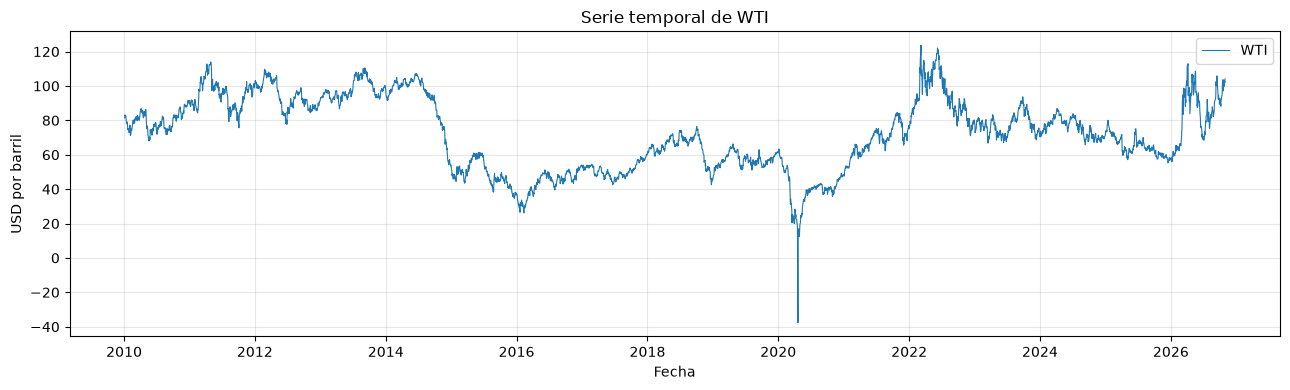

In [24]:
eda.graficar_serie_temporal(base["WTI"], nombre="WTI", unidad="USD por barril")

### 1.6 Tranformación de la serie

En la sección 1.1 se identificó un único precio negativo (20-abr-2020, −37.63 USD), producto del vencimiento del contrato de mayo y la falta de capacidad de almacenamiento. Como el logaritmo no está definido para valores ≤ 0, se elimina esta observación (1 de 4,233). El retorno del 21-abr-2020 se calcula respecto al 17-abr-2020 y se conserva como evento extremo real.

La serie de precios se transforma en retornos logarítmicos diarios (en %):


$$r_t = 100 \cdot \ln\left(\frac{P_t}{P_{t-1}}\right)$$

Se elige esta transformación porque:


- los retornos logarítmicos no dependen de la escala del precio y se interpretan como variación porcentual aproximada;
- son aditivos en el tiempo (el retorno de varios días es la suma de los retornos diarios);
- son la variable estándar en los modelos ARIMA/GARCH y en la literatura de pronóstico financiero.

In [25]:
base1,filas_eliminadas=eda.drop_nonpositive_rows(base)

In [26]:
base1

,WTI
Date,
2010-01-04,81.510002
2010-01-05,81.769997
2010-01-06,83.180000
2010-01-07,82.660004
2010-01-08,82.750000
...,...
2026-10-26,101.760002
2026-10-27,99.900002
2026-10-28,102.779999


In [27]:
filas_eliminadas

,WTI
Date,
2020-04-20,-37.630001


In [28]:
# La decisión vive en src/config.py (TRANSF). Si cambia el diagnóstico, se edita allí.
pd.Series(cfg.transf, name="transformación")

WTI    logret
Name: transformación, dtype: str

In [29]:
base_ret=pp.build_returns(base1)

In [30]:
base_ret

,WTI
Date,
2010-01-05,0.003185
2010-01-06,0.017097
2010-01-07,-0.006271
2010-01-08,0.001088
2010-01-11,-0.002783
...,...
2026-10-26,-0.014730
2026-10-27,-0.018447
2026-10-28,0.028421


## 2.División temporal de los datos

En series de tiempo no se puede dividir la muestra de forma aleatoria (k-fold clásico), porque el modelo usaría observaciones del futuro para predecir el pasado (fuga de información). Por eso la división respeta el orden cronológico:

- Train/Validation o Desarrollo (2010–2024): se usa para el diagnóstico de la serie, la optimización de hiperparámetros y la comparación estadística, mediante validación walk-forward.
- Test final (2025–oct 2026): se reserva y no se utiliza hasta la evaluación final de ambos modelos.

El periodo de desarrollo abarca de enero de 2010 a diciembre de 2024. El test final comprende de enero de 2025 a octubre de 2026 y funciona como verificación fuera de muestra: ambos modelos del proyecto se entrenarán con todo el desarrollo y se evalúan una sola vez en este periodo.

In [31]:
dev_ini=cfg.DEV_INI
dev_fin=cfg.DEV_FIN
test_ini=cfg.TEST_INI
test_fin=cfg.TEST_FIN

In [32]:
dev=base_ret.loc[dev_ini:dev_fin]
test=base_ret.loc[test_ini:test_fin]

In [33]:
dev

,WTI
Date,
2010-01-05,0.003185
2010-01-06,0.017097
2010-01-07,-0.006271
2010-01-08,0.001088
2010-01-11,-0.002783
...,...
2024-12-24,0.012344
2024-12-26,-0.006871
2024-12-27,0.013978


In [34]:
# Verificaciones
assert dev.index.max() < test.index.min()          # sin traslape
assert len(dev) + len(test) == len(base_ret)       # no se pierden observaciones

### 2.1 Validación walk-forward o Time Cross Validation 

Al ser una serie de tiempo indexada con las fechas diarias de negociación y con los retornos calculados, se empleará la validación walk forward con ventana expansiva o Time Series Cross-Validation (TSCV) en machine learning.
en cada fold, el modelo se entrena con todos los datos anteriores al bloque de validación y se evalúa en los 12 meses siguientes.

El intervalo de desarrollo (2010-2024) contiene el train y la validación, los cuales se van alternando en cada fold, es decir: 
- Train: todo lo anterior al bloque de validación de ese fold.
- Validación: los 12 meses siguientes.

Por ejemplo: 

| Fold | Train | Validación |
|---|---|---|
| Rep 1 · Fold 1 | 2010 → 2019 | 2020 |
| Rep 1 · Fold 2 | 2010 → 2020 | 2021 |
| Rep 1 · Fold 3 | 2010 → 2021 | 2022 |
| Rep 1 · Fold 4 | 2010 → 2022 | 2023 |
| Rep 1 · Fold 5 | 2010 → 2023 | 2024 |

Una característica importante de este procedimiento es que **un mismo período puede utilizarse primero como validación y posteriormente formar parte del entrenamiento**.

Por ejemplo, el año **2020**:

- Es utilizado como **validación** en el Fold 1.
- Posteriormente pasa a formar parte del **train** en los Folds 2, 3, 4 y 5.

Por lo tanto, a diferencia de una división tradicional *train/validation*, en Time Series Cross-Validation **no existe un único conjunto de entrenamiento ni un único conjunto de validación**. Ambos van cambiando a medida que se avanza temporalmente.

Este esquema también se conoce como **Expanding Window**, porque la ventana de entrenamiento se va expandiendo en cada iteración.


```text
base_ret (2010 → oct-2026)
│
├── Desarrollo (2010 → 2024)
│   │
│   ├── Train + Validación mediante Time Series Cross-Validation
│   │   └── El train se expande y la validación avanza en el tiempo
│   │
│   └── Se utiliza para:
│       ├── EDA
│       ├── Optimización de hiperparámetros con Optuna
│       └── Comparación y selección estadística de modelos
│
└── Test final (2025 → oct-2026)
    └── Se utiliza una sola vez al final para evaluar
        el desempeño real del modelo seleccionado
```

De esta manera se respeta el orden temporal de los datos: **Pasado → Futuro**

Nunca se utiliza información futura para entrenar un modelo que será evaluado en el pasado.


![Time Series Cross-Validation](../img/imagen1.1.png)

![Time Series Cross-Validation](../img/imagen1.png)

Se obtienen bloques de validación que cubren regímenes distintos (COVID-19, recuperación de 2021, guerra en Ucrania en 2022 y años más estables). Los dos modelos se evalúan exactamente en los mismos folds.

In [35]:
FOLDS = eda.definir_folds()

# Tabla de los folds
tabla_folds = FOLDS.copy()
tabla_folds[["n_train", "n_val"]] = [
    [len(a) for a in eda.indices_fold(dev.index, f)] for f in FOLDS.itertuples()]
for c in ["train_ini", "train_fin", "val_ini", "val_fin"]:
    tabla_folds[c] = tabla_folds[c].dt.date
display(tabla_folds)

assert (FOLDS["val_fin"] <= pd.Timestamp(dev_fin)).all()   # ningún fold toca el test final


,rep,fold,train_ini,train_fin,val_ini,val_fin,n_train,n_val
0,1,1,2010-01-01,2019-12-31,2020-01-01,2020-12-31,2513,252
1,1,2,2010-01-01,2020-12-31,2021-01-01,2021-12-31,2765,252
2,1,3,2010-01-01,2021-12-31,2022-01-01,2022-12-31,3017,251
3,1,4,2010-01-01,2022-12-31,2023-01-01,2023-12-31,3268,250
4,1,5,2010-01-01,2023-12-31,2024-01-01,2024-12-31,3518,252
5,2,1,2010-01-01,2019-06-30,2019-07-01,2020-06-30,2385,252
6,2,2,2010-01-01,2020-06-30,2020-07-01,2021-06-30,2637,252
7,2,3,2010-01-01,2021-06-30,2021-07-01,2022-06-30,2889,252
8,2,4,2010-01-01,2022-06-30,2022-07-01,2023-06-30,3141,251
9,2,5,2010-01-01,2023-06-30,2023-07-01,2024-06-30,3392,250


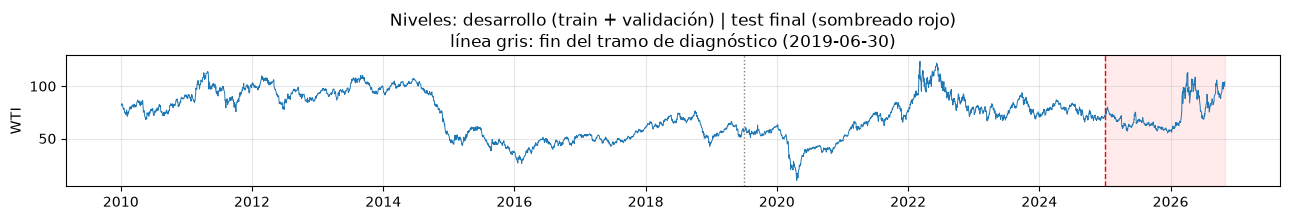

In [36]:
eda.graficar_niveles_con_cortes(base1)

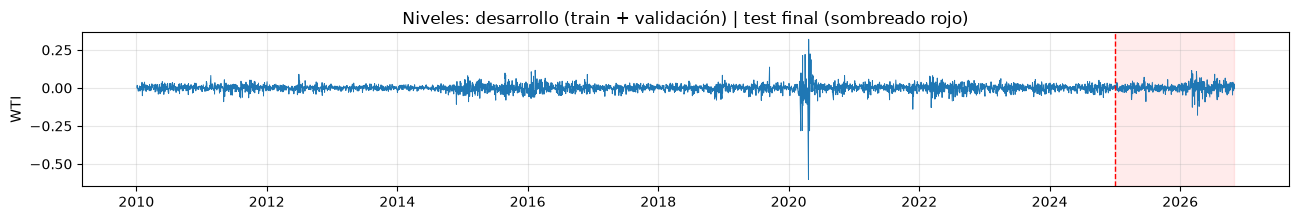

In [37]:
eda.graficar_niveles_con_cortes(base_ret,columnas=["WTI"], mostrar_eda=False)

### 2.2 Tramo para diagnósticos: 2010-2019 (train del primer fold)

Las pruebas que orientan la elección del modelo base (estacionariedad, estacionalidad, ACF/PACF, Ljung-Box y ARCH-LM) se aplicarán al tramo enero 2010 – junio 2019, el cual corresponde al periodo de entrenamiento más corto de todos los folds (Rep 2 · Fold 1). 

Así, ninguna decisión de modelado usa información de los bloques de validación ni del test final.

In [38]:
EDA_FIN = FOLDS["train_fin"].min()          # = 2019-06-30, el train más corto
train_ret = base_ret.loc[:EDA_FIN]

print(f"Tramo de diagnóstico: {train_ret.index.min().date()} → {train_ret.index.max().date()} "
      f"({len(train_ret)} obs, {100*len(train_ret)/len(dev):.1f}% del desarrollo)")
assert train_ret.index.max() < FOLDS["val_ini"].min()   # no toca ninguna validación

Tramo de diagnóstico: 2010-01-05 → 2019-06-28 (2385 obs, 63.3% del desarrollo)


In [39]:
train_ret

,WTI
Date,
2010-01-05,0.003185
2010-01-06,0.017097
2010-01-07,-0.006271
2010-01-08,0.001088
2010-01-11,-0.002783
...,...
2019-06-24,0.008151
2019-06-25,-0.001210
2019-06-26,0.026450


El tramo de diagnóstico (EDA) comprende desde el 5 de enero de 2010 hasta el 28 de junio de 2019, con un total de 2.385 observaciones, que representan el 63,3 % del conjunto de desarrollo (2010–2024).

Este período se utiliza para analizar el comportamiento histórico de las series financieras, identificar tendencias, volatilidad, estacionariedad, valores atípicos y relaciones entre variables, antes de realizar la validación temporal y el entrenamiento de los modelos predictivos.

## 3. EDA de la parte de train previa a la validación

### 3.1 Estadística Descriptiva

In [40]:
eda.descriptivos_precios(train_ret).T

serie,WTI
n,2385
media,-0.000139
std,0.020494
CV,-147.132587
min,-0.107942
fecha_min,2014-11-28
p25,-0.010823
mediana,0.000522
p75,0.010951
max,0.116213


El análisis descriptivo de los 2.385 log-retornos diarios del petróleo WTI de la parte de train seleccionada  correspondiente al período del 5 de enero de 2010 al 28 de junio de 2019, presenta los siguientes resultados:

- 	Rendimiento logarítmico promedio diario de aproximadamente -0,014 %, cercano a cero, con una ligera tendencia negativa.
- Volatilidad diaria de 2,05 %, que refleja la dispersión de los rendimientos respecto a su media.
- Mayor caída diaria observada, equivalente a un log-retorno de -10,79 % el 28 de Noviembre de 2014
- El 25 % de los rendimientos diarios fueron inferiores o iguales a -1,08 % en escala logarítmica.
- 	El 50 % de los rendimientos fueron inferiores o iguales a 0,052 %, evidenciando un rendimiento central ligeramente positivo.
- Mayor incremento diario observado, equivalente a un log-retorno de 11,62 % el 12 de Febrero de 2016.
- Asimetría (Skewness = -0,0171): indica que la distribución es prácticamente simétrica, con una ligera asimetría negativa. Por tanto, no se evidencia una inclinación significativa de la distribución hacia rendimientos negativos o positivos.
- Curtosis en exceso (2,9174): indica que la distribución es leptocúrtica, es decir, presenta colas más pesadas que una distribución normal, lo que sugiere mayor frecuencia de movimientos extremos.  Una distribución leptocúrtica significa que existe una mayor presencia de valores extremos (tanto negativos como positivos) en comparación con una distribución normal



### 3.2 Distribución, Estacionariedad, Estacionalidad y otras métricas

Para la estacionariedad se valida que:

- **ADF (Dickey Fuller Aumentada)**: $H_0$ = la serie tiene raíz unitaria (no estacionaria).
- **KPSS(Kwiatkowski-Phillips-Schmidt-Shin)**: $H_0$ = la serie es estacionaria.
- **PP (Philiphs-Perron)**:  $H_0$ = la serie tiene raíz unitaria (no estacionaria).

Se usan las dos porque tienen hipótesis nulas opuestas. La conclusión es fuerte cuando ambas coinciden.

In [46]:
eda.diagnostico_estacionariedad(train_ret).T

,0
serie,WTI
n,2385
ADF_stat,-34.4008
ADF_p,0.0
KPSS_stat,0.079
KPSS_p,0.1
PP_stat,-51.9578
PP_p,0.0
PP_lags,27


Los resultados sugieren que los retornos diarios del WTI en el conjunto de entrenamiento son estacionarios:

- ADF: estadístico = −34.40, p = 0.0 (redondeado por la salida). La prueba ADF tiene como hipótesis nula que la serie posee una raíz unitaria; el p-valor tan pequeño permite rechazarla (menor a 0.05).
- PP: estadístico = −52.95, p = 0.0 (redondeado por la salida). La prueba PP tiene como hipótesis nula que la serie posee una raíz unitaria; el p-valor tan pequeño permite rechazarla (menor a 0.05).
- KPSS: estadístico = 0.079, p = 0.1. La hipótesis nula de KPSS es que la serie es estacionaria; con ese p-valor no se rechaza (mayor a 0.05).

Como las tres pruebas apuntan en la misma dirección —ADF y PP rechazan no estacionariedad y KPSS no rechaza estacionariedad—, hay evidencia consistente de estacionariedad en train_ret.

La estacionalidad es la repetición de patrones en intervalos regulares de tiempo, como cambios que suelen ocurrir cada mes, trimestre o año. En una serie de retornos, puede reflejarse, por ejemplo, en que el retorno promedio varíe según el mes o en que exista dependencia entre observaciones separadas por un número fijo de períodos.

La prueba de Kruskal–Wallis compara varios grupos cuando no se quiere asumir que los datos siguen una distribución normal. En vez de comparar directamente las medias, ordena todas las observaciones de menor a mayor y compara los rangos entre grupos. En este caso, los grupos son los meses y los datos son los retornos del WTI de cada mes.

- Kruskal–Wallis — $H_{0}$: los grupos provienen de la misma distribución.




In [50]:
eda.diagnostico_estacionalidad(train_ret).T

,0
serie,WTI
n,2385
Kruskal_mes_p,0.504
ACF_5,0.0242
ACF_21,0.0016
ACF_252,0.0319


- Kruskal_mes_p = 0.504: p-valor de Kruskal–Wallis, que compara la distribución de los retornos entre meses. Como es mayor que 0.05, no se rechaza $H_{0}$; la prueba no encuentra evidencia de diferencias entre meses.
- ACF_5 = 0.0242, ACF_21 = 0.0016 y ACF_252 = 0.0319: autocorrelación de los retornos separados por 5, 21 y 252 observaciones, respectivamente. Son valores cercanos a cero, lo que sugiere poca relación lineal con los retornos de esos rezagos.

En conjunto, estos resultados no muestran evidencia clara de un patrón mensual ni de autocorrelación importante en esos rezagos.

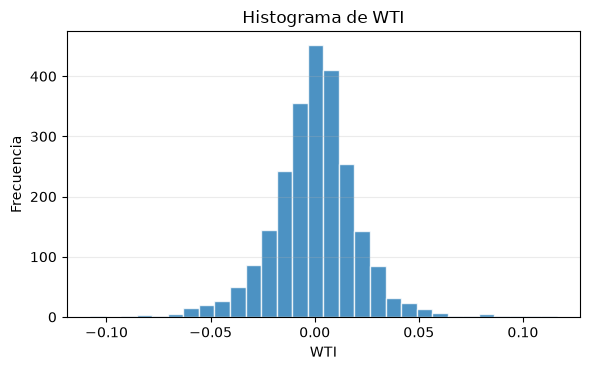

(<Figure size 600x380 with 1 Axes>,
 array([[<Axes: title={'center': 'Histograma de WTI'}, xlabel='WTI', ylabel='Frecuencia'>]],
       dtype=object))

In [56]:
eda.graficar_histograma(train_ret)

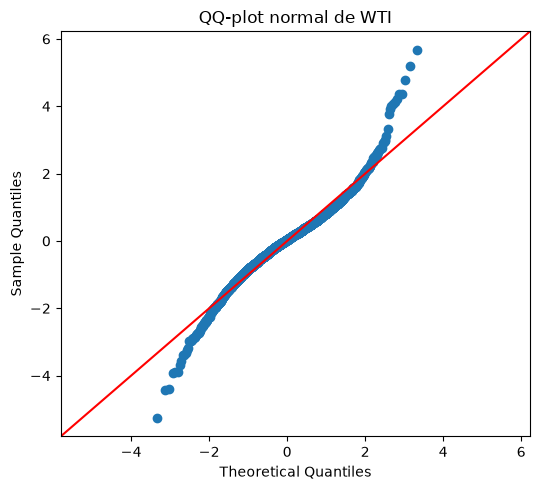

(<Figure size 550x500 with 1 Axes>,
 array([[<Axes: title={'center': 'QQ-plot normal de WTI'}, xlabel='Theoretical Quantiles', ylabel='Sample Quantiles'>]],
       dtype=object))

In [60]:
eda.graficar_qqplot(train_ret)

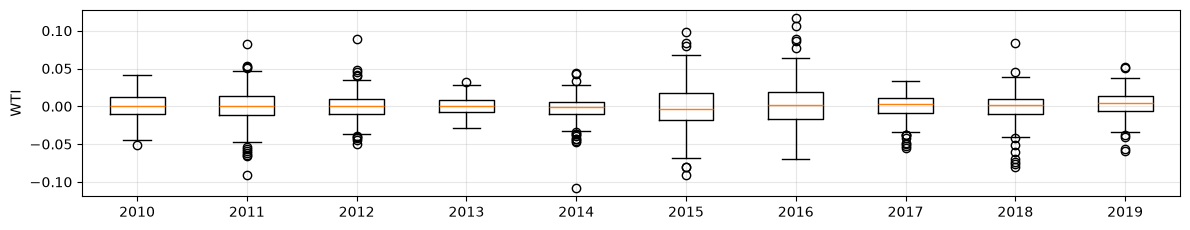

In [53]:
eda.graficar_boxplot_anual(train_ret)

In [ ]:
### VER COLAS PESADAS

### 3.3 Dependencia temporal de los retornos

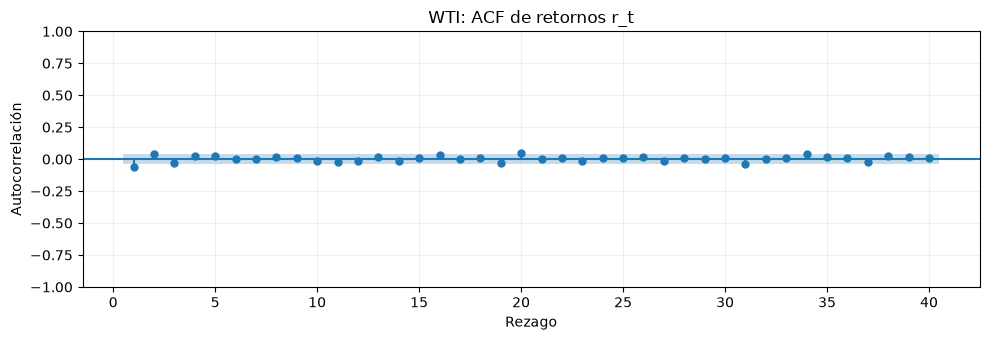

In [64]:
fig, axes, tabla_lb = eda.graficar_acf_con_pvalores(train_ret)

Ljung–Box $H_{0}$: no existe autocorrelación conjunta en los retornos del WTI hasta el rezago evaluado.

In [66]:
tabla_lb.T

serie,WTI
n,2385.0000
LB_Q(5),18.5579
LB_p(5),0.0023
LB_Q(21),32.4203
LB_p(21),0.0531
LB_Q(252),297.2663
LB_p(252),0.0264


- Hasta el rezago 5: p-valor = 0.0023. Como es menor que 0.05, se rechaza $H_{0}$; hay evidencia de autocorrelación conjunta hasta ese rezago.
- Hasta el rezago 21: p-valor = 0.0531. Como es mayor que 0.05, no se rechaza $H_{0}$ al nivel de significancia del 5%.
- Hasta el rezago 252: p-valor = 0.0264. Como es menor que 0.05, se rechaza $H_{0}$; hay evidencia de autocorrelación conjunta hasta ese rezago.

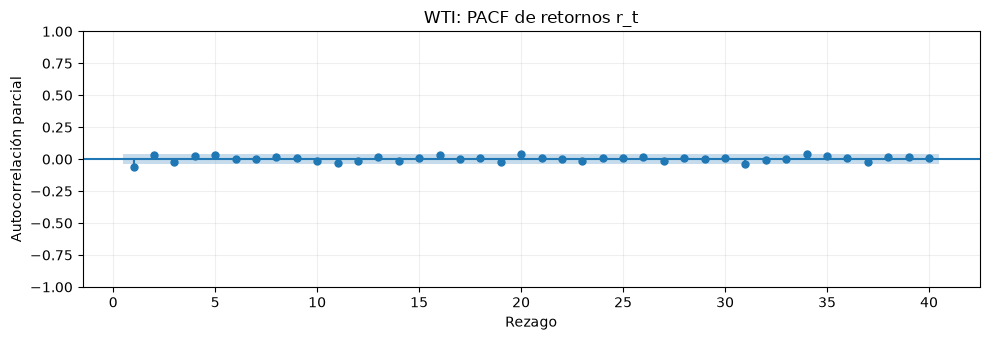

In [71]:
fig, axes, tabla_pacf = eda.graficar_pacf_con_pvalores(train_ret)

Las autocorrelaciones parciales del gráfico son pequeñas y están cerca de cero, así que no se observa una relación directa fuerte entre los retornos actuales y los retornos pasados hasta el rezago 40, una vez controlados los rezagos intermedios.

In [72]:
display(tabla_pacf)

PACF  p_aprox
serie rezago                 
WTI   1      -0.0647   0.0016
      2       0.0342   0.0951
      3      -0.0246   0.2304
      4       0.0219   0.2847
      5       0.0293   0.1529
      6       0.0031   0.8778
      7      -0.0018   0.9281
      8       0.0142   0.4895
      9       0.0087   0.6724
      10     -0.0161   0.4305
      11     -0.0266   0.1935
      12     -0.0175   0.3931
      13      0.0167   0.4140
      14     -0.0130   0.5269
      15      0.0086   0.6728
      16      0.0354   0.0838
      17      0.0037   0.8556
      18      0.0075   0.7157
      19     -0.0240   0.2411
      20      0.0405   0.0480
      21      0.0060   0.7684
      22      0.0002   0.9923
      23     -0.0117   0.5667
      24      0.0058   0.7755
      25      0.0069   0.7353
      26      0.0177   0.3863
      27     -0.0107   0.6004
      28      0.0092   0.6522
      29      0.0004   0.9857
      30      0.0092   0.6516
      31     -0.0366   0.0740
      32     -0.0030   0.8837
      33      0.0050   0.8074
      34      0.0412   0.0442
      35      0.0216   0.2912
      36      0.0074   0.7190
      37     -0.0245   0.2308
      38      0.0200   0.3294
      39      0.0186   0.3643
      40      0.0081   0.6922

La tabla muestra la PACF y un p-valor aproximado para cada rezago individual del WTI:
- En el rezago 1, PACF = −0.0647 y p = 0.0016: hay evidencia de una autocorrelación parcial negativa, aunque pequeña.
- En los rezagos 20 y 34, los p-valores también son menores que 0,05 (0.0480 y 0.0442), pero sus coeficientes son pequeños: 0.0405 y 0.0412.
- Los p-valores de los demás rezagos visibles son mayores que 0,05; para ellos no hay evidencia suficiente de una PACF distinta de cero al nivel del 5%.
En términos prácticos, las asociaciones estimadas son débiles. Además, como se están evaluando 40 rezagos por separado, algunos p-valores pueden quedar por debajo de 0,05 solo por azar.

### 3.4 Dependencia temporal de la volatilidad

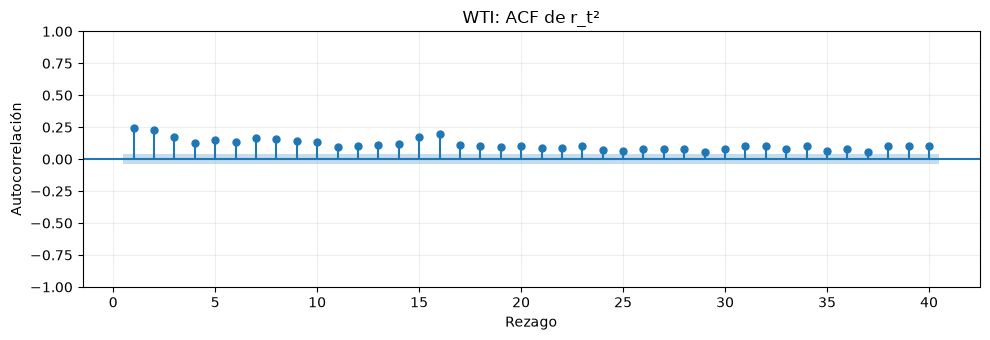

In [77]:
fig, axes, tabla_lb_r2 = eda.graficar_acf_con_pvalores(
    train_ret.pow(2),
    etiqueta="r_t²"
)

La gráfica muestra la función de autocorrelación (ACF) de los retornos al cuadrado \(r_t^2\) del WTI. Al elevar los retornos al cuadrado, se observa principalmente la magnitud de los movimientos, sin importar si fueron positivos o negativos.

Las barras son positivas y muchas superan la banda de confianza cercana a cero. Esto sugiere que los retornos al cuadrado tienen autocorrelación persistente: los periodos de movimientos grandes tienden a agruparse, al igual que los periodos de movimientos pequeños. A este patrón se le suele llamar agrupamiento de volatilidad (volatility clustering).

Esto indica que la volatilidad podría depender de valores pasados y que sería útil evaluar modelos ARCH/GARCH.

In [78]:
tabla_lb_r2.T

serie,WTI
n,2385.0000
LB_Q(5),430.9515
LB_p(5),0.0000
LB_Q(21),1087.5299
LB_p(21),0.0000
LB_Q(252),2822.3607
LB_p(252),0.0000


La tabla presenta la prueba de Ljung–Box aplicada a los retornos al cuadrado \(r_t^2\), para detectar si existe autocorrelación conjunta hasta distintos rezagos.

- \(Q\) (LB_Q): estadístico de Ljung–Box. Cuanto mayor sea, más evidencia hay contra la hipótesis de que no existe autocorrelación hasta ese rezago.
- \(p\) (LB_p): valor p usado para decidir si esa evidencia es estadísticamente significativa.
- \(n=2385\): número de observaciones.

En los tres horizontes, los valores p son 0.0, menor que el nivel  de significancia de 0.05. Por ello, se rechaza la hipótesis nula de ausencia de autocorrelación hasta los rezagos 5, 21 y 252.

**Conclusión:** los retornos al cuadrado presentan dependencia temporal significativa. Esto respalda lo que sugiere la ACF: hay agrupamiento de volatilidad en los retornos del WTI. Podrías evaluar un modelo ARCH/GARCH para modelar esa dinámica.

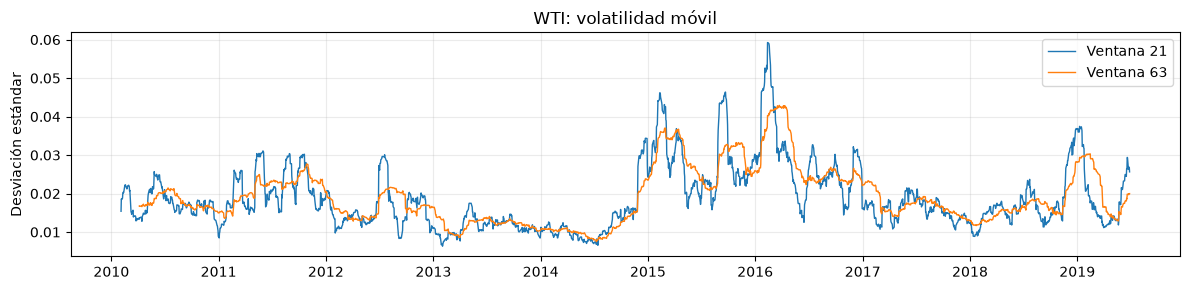

(<Figure size 1200x300 with 1 Axes>,
 array([<Axes: title={'center': 'WTI: volatilidad móvil'}, ylabel='Desviación estándar'>],
       dtype=object))

In [81]:
eda.graficar_volatilidad_movil(train_ret["WTI"], ventanas=(21, 63))

La gráfica muestra la volatilidad móvil de los retornos del WTI, calculada como la desviación estándar en ventanas de 21 y 63 observaciones.

- Ventana 21 (azul): calcula la desviación estándar usando las últimas 21 observaciones en cada punto. Si los datos son diarios de mercado, equivale aproximadamente a un mes bursátil. Reacciona rápido a cambios recientes, por eso la línea se ve más irregular y alcanza picos más abruptos.
- Ventana 63 (naranja): usa las últimas 63 observaciones, aproximadamente tres meses bursátiles. Suaviza más los cambios y tarda más en subir o bajar porque incorpora un periodo mayor.


La ventana se aplica sobre la serie de retornos: para resumir cuánto han variado los retornos recientemente. La línea azul puede verse más “expandida” porque refleja cambios de corto plazo con mayor rapidez; la naranja promedia la volatilidad durante más tiempo. Los picos indican periodos en que los retornos fluctuaron más, no necesariamente que los precios subieran: la desviación estándar mide variabilidad en ambas direcciones.

La gráfica muestra que la volatilidad de los retornos del WTI cambia con el tiempo; no permanece en un nivel constante. Se observan periodos relativamente tranquilos, como 2013–2014, y episodios de mayor variabilidad, especialmente entre 2015 y 2016, donde la volatilidad de corto plazo (ventana 21) alcanza su máximo, cercano a 0.06.

La línea de 21 observaciones responde con más rapidez y presenta picos pronunciados. La de 63 observaciones es más suave y muestra la persistencia de esos episodios durante periodos más largos. En conjunto, esto sugiere agrupamiento de volatilidad: los periodos de alta variabilidad tienden a mantenerse por un tiempo.

La gráfica describe la variabilidad de los retornos, no la dirección de los precios: un aumento de volatilidad no indica por sí solo si el WTI subió o bajó.

In [85]:
r = train_ret["WTI"].dropna()

modelo_media = ARIMA(r, order=(1, 0, 0), trend="c").fit()
residuos_media = modelo_media.resid


In [87]:
tabla_arch = eda.diagnostico_arch_lm(modelo_media.resid, lags=10)
tabla_arch.T

serie,serie
n,2385.0000
ARCH_LM_stat,296.4097
ARCH_LM_p,0.0000
ARCH_F_stat,33.7109
ARCH_F_p,0.0000
lags,10.0000


La prueba ARCH-LM evalúa si los residuos del modelo de media tienen efectos ARCH, es decir, si su varianza depende de errores pasados. Esto ayuda a determinar si la volatilidad está cambiando en el tiempo.

La hipótesis nula es que no hay efectos ARCH hasta 10 rezagos. En tu tabla:
- lags = 10: se evalúan los últimos 10 rezagos.
- ARCH_LM_stat = 296.4097: estadístico de la prueba LM.
- ARCH_LM_p = 0.0: el valor p aparece como cero por redondeo; no debe interpretarse como exactamente cero.
- La prueba F da el mismo tipo de conclusión: ARCH_F = 33.7109 y ARCH_F_p = 0.0.


Como ambos valores p son extremadamente pequeños (menores que 0.05), se rechaza la hipótesis nula. Hay evidencia estadística de efectos ARCH en los residuos del modelo de media: su volatilidad no es constante y depende de valores pasados.

Por lo tanto, tiene sentido probar un modelo de volatilidad como ARCH/GARCH. Esta prueba identifica dependencia en la varianza, pero por sí sola no determina qué modelo específico es el mejor.

### 3.5 Conclusiones del EDA.

Qué indican los resultados
- Precios: la gráfica y los cambios de nivel sugieren que la serie de precios no es estacionaria. Sin embargo, en el notebook las pruebas ADF/KPSS/PP se aplicaron a train_ret, no a los precios. Para afirmar formalmente que el precio no es estacionario, faltaría aplicarles las pruebas a los niveles del precio.
- Retornos: ADF y PP reportan p = 0.0, y KPSS p = 0.1. Son valores redondeados: ADF y PP rechazan la hipótesis de raíz unitaria, y KPSS no rechaza la estacionariedad. La evidencia respalda modelar los retornos, que son estacionarios.
- Dependencia en la media: la ACF/PACF de los retornos es pequeña. Aun así, Ljung–Box da p = 0.0023 hasta el rezago 5 y p = 0.0264 hasta el 252, evidencia de autocorrelación conjunta débil. La PACF del rezago 1 es −0.0647 (p ≈ 0.0016); los resultados de los rezagos 20 y 34 son apenas significativos y deben tomarse con cautela porque se probaron 40 rezagos.
- Estacionalidad mensual: Kruskal–Wallis da p = 0.504; no encuentra evidencia de que la distribución de los retornos cambie entre meses. Esto no descarta toda forma de estacionalidad, pero no justifica añadir términos estacionales con la evidencia actual.
- Distribución: la asimetría es casi cero (−0.017), pero el exceso de curtosis es alto (2.917) y Jarque–Bera rechaza normalidad. Los retornos tienen colas más pesadas que una normal; una distribución t de Student es una opción razonable para probar.
- Dependencia en la volatilidad: la ACF de r_t² muestra dependencia conjunta muy significativa: Ljung–Box da p = 0.0000 hasta los rezagos 5, 21 y 252. Además, la volatilidad móvil presenta agrupamientos, y ARCH–LM sobre los residuos de la media AR(1) da p = 0.0000 con 10 rezagos. Esto es evidencia fuerte de efectos ARCH.

Como candidato inicial se propone AR(1)–GARCH(1,1) con errores t, comparándolo con modelos más simples mediante validación temporal.

In [88]:
p = base1["WTI"].loc[:EDA_FIN]
dP = p.diff()
r  = 100 * np.log(p / p.shift(1))

comp = pd.DataFrame({
    "precio_medio": p.resample("YE").mean(),
    "std_diferencia_USD": dP.resample("YE").std(),
    "std_retorno_%": r.resample("YE").std(),
})
display(comp.round(2))
print("Corr(precio, std ΔP):", comp["precio_medio"].corr(comp["std_diferencia_USD"]).round(2))
print("Corr(precio, std r) :", comp["precio_medio"].corr(comp["std_retorno_%"]).round(2))

,precio_medio,std_diferencia_USD,std_retorno_%
Date,,,
2010-12-31,79.61,1.35,1.73
2011-12-31,95.11,2.05,2.20
2012-12-31,94.21,1.50,1.64
2013-12-31,98.05,1.13,1.15
2014-12-31,92.91,1.24,1.53
2015-12-31,48.76,1.42,2.96
2016-12-31,43.44,1.17,2.97
2017-12-31,50.85,0.79,1.59
2018-12-31,64.95,1.19,1.98


Corr(precio, std ΔP): 0.5
Corr(precio, std r) : -0.65
